# Projeto U2 - Ajuste de Curvas

Modelo: `s[n] = f(s[n-1], s[n-2], u[n], u[n-1])`, para as saídas x e y.

- RBF: f é uma soma de gaussianas
- MMQ: f = a1·s[n-1] + a2·s[n-2] + b0·u[n] + b1·u[n-1]

## 1. Leitura dos dados

In [1]:
import csv
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True)  # sem notação científica

# o csv usa vírgula nos números, então troco por ponto
dados = []
with open("dados_projeto_02.csv", encoding="utf-8") as arq:
    leitor = csv.reader(arq)
    next(leitor)  # pula o cabeçalho
    for linha in leitor:
        dados.append([float(v.replace(",", ".")) for v in linha])
dados = np.array(dados)

t = dados[:, 0]
u = dados[:, 1]
x = dados[:, 2]
y = dados[:, 3]
print(len(t), "amostras")

1501 amostras


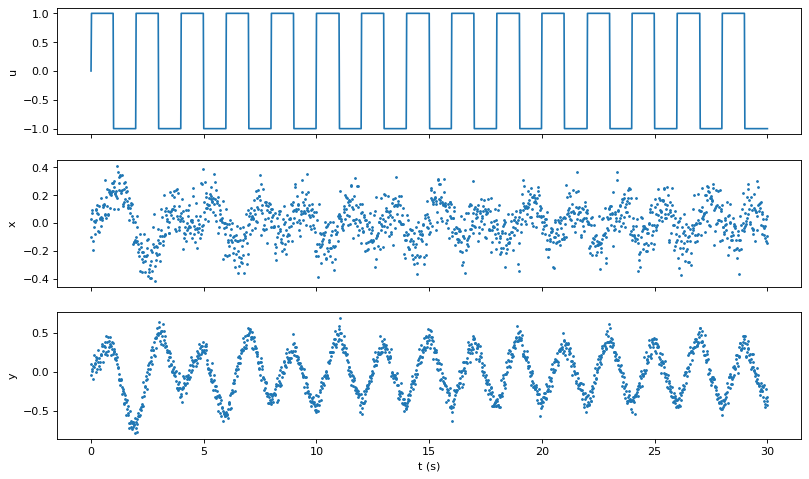

In [2]:
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(t, u)
ax[0].set_ylabel("u")
ax[1].plot(t, x, ".", ms=3)
ax[1].set_ylabel("x")
ax[2].plot(t, y, ".", ms=3)
ax[2].set_ylabel("y")
ax[2].set_xlabel("t (s)")
plt.show()

## 2. Funções

In [3]:
def emq(real, previsto):
    return np.mean((real - previsto) ** 2)

def pearson(a, b):
    da = a - np.mean(a)
    db = b - np.mean(b)
    return np.sum(da * db) / np.sqrt(np.sum(da ** 2) * np.sum(db ** 2))

def regressao_linear(xr, yr):
    # reta yr = alfa + beta * xr (sistema 2x2)
    A = np.array([[len(xr), np.sum(xr)],
                  [np.sum(xr), np.sum(xr ** 2)]])
    B = np.array([np.sum(yr), np.sum(xr * yr)])
    alfa, beta = np.linalg.solve(A, B)
    return alfa, beta

def minimos_quadrados(A, alvo):
    # equação normal: (A^T A) w = A^T alvo
    return np.linalg.solve(A.T @ A, A.T @ alvo)

## 3. Montando as entradas

In [4]:
# cada linha: [s[n-1], s[n-2], u[n], u[n-1]]   e o alvo é s[n]
def montar(s):
    Z = np.column_stack([s[1:-1], s[:-2], u[2:], u[1:-1]])
    alvo = s[2:]
    return Z, alvo

Zx, alvo_x = montar(x)
Zy, alvo_y = montar(y)
tn = t[2:]
print(Zx.shape)

(1499, 4)


## 4. RBF

In [5]:
def gaussianas(Z, centros, sigma):
    Phi = np.ones((len(Z), len(centros) + 1))  # primeira coluna = 1 (peso w0)
    for j in range(len(centros)):
        d2 = np.sum((Z - centros[j]) ** 2, axis=1)
        Phi[:, j + 1] = np.exp(-d2 / (2 * sigma ** 2))
    return Phi

def escolher_centros(Z, k=4):
    # k centros para cada combinação de (u[n], u[n-1]),
    # pegando linhas espaçadas depois de ordenar por s[n-1]
    centros = []
    for un, ua in [(1, 1), (-1, -1), (1, -1), (-1, 1)]:
        linhas = np.where((Z[:, 2] == un) & (Z[:, 3] == ua))[0]
        linhas = linhas[np.argsort(Z[linhas, 0])]
        pos = np.linspace(0, len(linhas) - 1, k).astype(int)
        centros.append(Z[linhas[pos]])
    return np.vstack(centros)

In [6]:
# testando alguns sigmas
for sigma in [0.2, 0.3, 0.5, 1.0]:
    for Z, alvo, nome in [(Zx, alvo_x, "x"), (Zy, alvo_y, "y")]:
        C = escolher_centros(Z)
        Phi = gaussianas(Z, C, sigma)
        w = minimos_quadrados(Phi, alvo)
        print("sigma =", sigma, nome, "EMQ =", round(emq(alvo, Phi @ w), 5))

sigma = 0.2 x EMQ = 0.01228
sigma = 0.2 y EMQ = 0.01563
sigma = 0.3 x EMQ = 0.01217
sigma = 0.3 y EMQ = 0.00787
sigma = 0.5 x EMQ = 0.01215
sigma = 0.5 y EMQ = 0.00759
sigma = 1.0 x EMQ = 0.01213
sigma = 1.0 y EMQ = 0.00743


In [7]:
# escolhi sigma = 0.5: a partir dele o erro quase não diminui
sigma = 0.5

Cx = escolher_centros(Zx)
Cy = escolher_centros(Zy)
wx = minimos_quadrados(gaussianas(Zx, Cx, sigma), alvo_x)
wy = minimos_quadrados(gaussianas(Zy, Cy, sigma), alvo_y)

x_rbf = gaussianas(Zx, Cx, sigma) @ wx
y_rbf = gaussianas(Zy, Cy, sigma) @ wy

print("centros:", len(Cx), "| pesos:", len(wx))
print("pesos x:", np.round(wx, 3))
print("pesos y:", np.round(wy, 3))

centros: 16 | pesos: 17
pesos x: [  0.017  -0.889   2.656  -2.345   0.485  -0.332   0.359  -0.135   0.084
  -2.138   3.135  -1.187   0.017  14.188 -45.865  33.718  -1.581]
pesos y: [ -0.143  -0.46    0.128  -0.088   0.633  -0.502   0.084  -0.013   0.64
  -4.07   31.708 -43.394  15.396   2.404  -5.778   3.365   0.738]


EMQ x (RBF): 0.01215
EMQ y (RBF): 0.00759


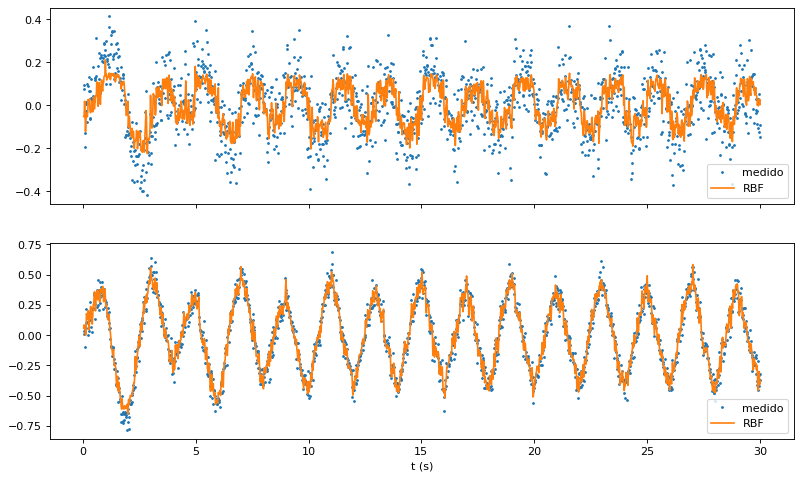

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(tn, alvo_x, ".", ms=3, label="medido")
ax[0].plot(tn, x_rbf, label="RBF")
ax[0].legend()
ax[1].plot(tn, alvo_y, ".", ms=3, label="medido")
ax[1].plot(tn, y_rbf, label="RBF")
ax[1].legend()
ax[1].set_xlabel("t (s)")
plt.show()

print("EMQ x (RBF):", round(emq(alvo_x, x_rbf), 5))
print("EMQ y (RBF):", round(emq(alvo_y, y_rbf), 5))

### Regressão linear (medido x ajustado) e Pearson

x RBF -> alfa = 0.0 beta = 1.0 r = 0.6403
y RBF -> alfa = 0.0 beta = 1.0 r = 0.9536


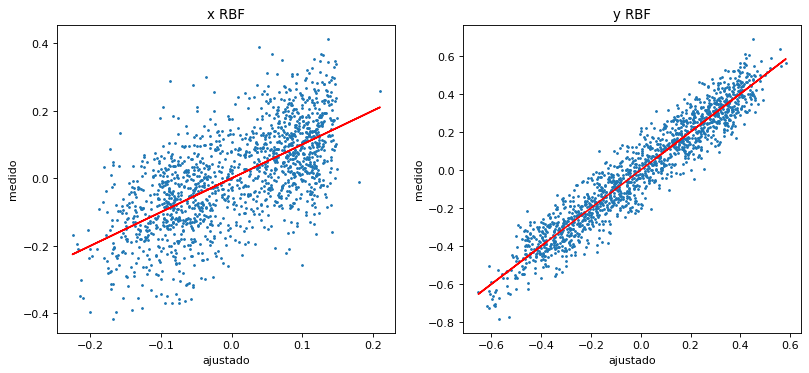

In [9]:
def grafico_regressao(ajustado, real, titulo):
    alfa, beta = regressao_linear(ajustado, real)
    r = pearson(real, ajustado)
    plt.plot(ajustado, real, ".", ms=3)
    plt.plot(ajustado, alfa + beta * ajustado, "r")
    plt.xlabel("ajustado")
    plt.ylabel("medido")
    plt.title(titulo)
    print(titulo, "-> alfa =", round(alfa, 4) + 0.0, "beta =", round(beta, 4), "r =", round(r, 4))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
grafico_regressao(x_rbf, alvo_x, "x RBF")
plt.subplot(1, 2, 2)
grafico_regressao(y_rbf, alvo_y, "y RBF")
plt.show()

## 5. MMQ

In [10]:
# aqui a matriz é o próprio Z: 4 parâmetros (a1, a2, b0, b1)
th_x = minimos_quadrados(Zx, alvo_x)
th_y = minimos_quadrados(Zy, alvo_y)
print("x: a1, a2, b0, b1 =", np.round(th_x, 4))
print("y: a1, a2, b0, b1 =", np.round(th_y, 4))

x_mmq = Zx @ th_x
y_mmq = Zy @ th_y

x: a1, a2, b0, b1 = [ 0.2984  0.2118 -0.0216 -0.015 ]
y: a1, a2, b0, b1 = [ 0.4876  0.4649 -0.0159  0.0426]


EMQ x (MMQ): 0.01226
EMQ y (MMQ): 0.00753


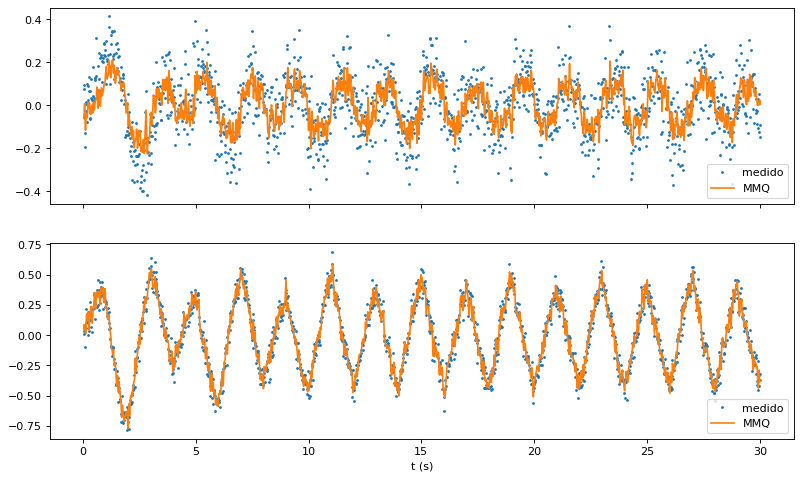

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(tn, alvo_x, ".", ms=3, label="medido")
ax[0].plot(tn, x_mmq, label="MMQ")
ax[0].legend()
ax[1].plot(tn, alvo_y, ".", ms=3, label="medido")
ax[1].plot(tn, y_mmq, label="MMQ")
ax[1].legend()
ax[1].set_xlabel("t (s)")
plt.show()

print("EMQ x (MMQ):", round(emq(alvo_x, x_mmq), 5))
print("EMQ y (MMQ):", round(emq(alvo_y, y_mmq), 5))

x MMQ -> alfa = 0.0022 beta = 0.9995 r = 0.6361
y MMQ -> alfa = -0.0007 beta = 1.0 r = 0.9541


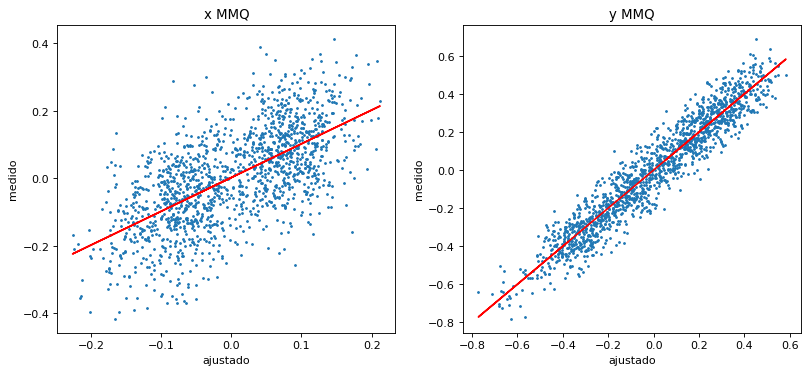

In [12]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
grafico_regressao(x_mmq, alvo_x, "x MMQ")
plt.subplot(1, 2, 2)
grafico_regressao(y_mmq, alvo_y, "y MMQ")
plt.show()

## 6. Comparação

In [13]:
print("modelo  saida   EMQ      r")
print("RBF     x      ", round(emq(alvo_x, x_rbf), 5), round(pearson(alvo_x, x_rbf), 4))
print("RBF     y      ", round(emq(alvo_y, y_rbf), 5), round(pearson(alvo_y, y_rbf), 4))
print("MMQ     x      ", round(emq(alvo_x, x_mmq), 5), round(pearson(alvo_x, x_mmq), 4))
print("MMQ     y      ", round(emq(alvo_y, y_mmq), 5), round(pearson(alvo_y, y_mmq), 4))

modelo  saida   EMQ      r
RBF     x       0.01215 0.6403
RBF     y       0.00759 0.9536
MMQ     x       0.01226 0.6361
MMQ     y       0.00753 0.9541


## 7. Conclusões

- RBF e MMQ deram praticamente o mesmo erro. Então o sistema é quase linear e o MMQ, com só 4 parâmetros, já basta (a RBF tem 17).
- y foi bem modelado (r perto de 0,95). x foi bem pior, porque tem muito mais ruído.
- Na regressão medido x ajustado, a reta ficou perto de inclinação 1 e intercepto 0, então os modelos não erram sempre para o mesmo lado.
- O EMQ mostra o tamanho do erro e o Pearson mostra se a forma da curva foi acompanhada.